# 05 — Agentic plane: from forecasts to operational decisions

The decision layer on top of the federated plane. Three agent roles, each a section below:

| agent | question it answers | section |
|---|---|---|
| **monitoring** | which `(trust, specialty)` units are in trouble *now*? | status flags |
| **planning** | where is the backlog heading, and what capacity closes the gap? | 12-month projection |
| **orchestration** | has demand shifted enough that the federation should retrain? | drift trigger |

**Privacy boundary preserved:** everything here consumes only aggregate series and model
outputs — the same tables the federated server may legally see; never raw local rows.

**Demand forecast used**: same-month-last-year × recent 12m/12m growth — a deliberately simple,
swappable stand-in. When the A100 sweep picks the winning forecaster, it plugs in here
unchanged (this notebook only needs a `(series, month) -> demand` function).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/rtt_long.csv")
net = json.load(open("../config/nhs_network.json"))
region_of = {t["code"]: r["region"] for r in net["regions"] for t in r["trusts"]}

# one row per (trust, specialty, month): demand, backlog, throughput, waiting shares
key = ["provider_code", "specialty_code", "month"]
cnt = df.pivot_table(index=key, columns="part", values="total_all", aggfunc="sum")
w = pd.DataFrame({"demand": cnt["Part_3"], "backlog": cnt["Part_2"],
                  "throughput": cnt["Part_1A"].fillna(0) + cnt["Part_1B"].fillna(0)}).reset_index()
bands = df[df["part"] == "Part_2"].groupby(key)[["weeks_0_18", "weeks_18_52", "weeks_52_plus"]].sum()
w = w.merge(bands.reset_index(), on=key, how="left").fillna(0)
w["share18"] = (w["weeks_18_52"] + w["weeks_52_plus"]) / \
               (w["weeks_0_18"] + w["weeks_18_52"] + w["weeks_52_plus"]).clip(lower=1)
w["region"] = w["provider_code"].map(region_of)

# same complete-series rule as notebook 03
months = sorted(w["month"].unique())
ok = w[w["demand"] > 0].groupby(["provider_code", "specialty_code"])["month"].nunique()
w = w.set_index(["provider_code", "specialty_code"]).loc[ok[ok == len(months)].index].reset_index()
LAST = months[-1]
print(f"series: {w.groupby(['provider_code','specialty_code']).ngroups} | latest month: {LAST}")

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
})

series: 694 | latest month: 2026-03


## Monitoring agent — status flags at the latest month

Rule (thresholds tied to the NHS constitution, not invented):
- **GREEN** — ≤ 8% of waiters past 18 weeks (the constitutional standard: 92% within 18w)
- **AMBER** — standard missed, but backlog *shrinking* (3-month mean outflow ≥ inflow)
- **RED** — standard missed AND backlog *growing* (inflow > outflow)

flag
RED      482
AMBER    170
GREEN     42


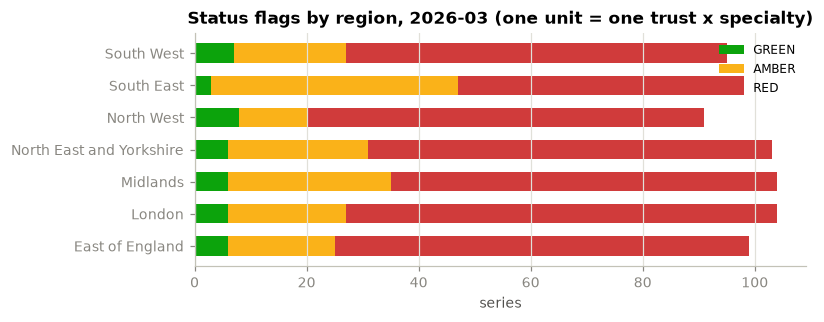

In [2]:
ser = ["provider_code", "specialty_code"]
cur = w[w["month"] == LAST].copy()
flow3 = w[w["month"] >= months[-3]].groupby(ser).apply(
    lambda g: (g["demand"] - g["throughput"]).mean(), include_groups=False).rename("net_flow_3m")
cur = cur.merge(flow3.reset_index(), on=ser)

cur["flag"] = np.where(cur["share18"] <= 0.08, "GREEN",
              np.where(cur["net_flow_3m"] > 0, "RED", "AMBER"))
print(cur["flag"].value_counts().to_string())

# status colors (reserved palette; labels carry meaning, never color alone)
STATUS = {"GREEN": "#0ca30c", "AMBER": "#fab219", "RED": "#d03b3b"}
byreg = cur.groupby(["region", "flag"]).size().unstack(fill_value=0)[["GREEN", "AMBER", "RED"]]
fig, ax = plt.subplots(figsize=(7.5, 3))
left = np.zeros(len(byreg))
for flag in ["GREEN", "AMBER", "RED"]:
    ax.barh(byreg.index, byreg[flag], left=left, color=STATUS[flag], height=0.6, label=flag)
    left += byreg[flag].values
ax.set_title(f"Status flags by region, {LAST} (one unit = one trust x specialty)")
ax.set_xlabel("series")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## Planning agent — 12-month backlog projection + capacity gap

Flow identity: `backlog(t+1) = backlog(t) + demand(t+1) − throughput(t+1)`.
Demand forecast = same month last year × recent-growth factor; throughput held at its
6-month mean ("do nothing" scenario). **Capacity gap** = extra treatments/month needed to
keep the backlog from growing.

units with growing backlog under do-nothing: 514 of 694
network capacity gap: 132,456 extra treatments/month


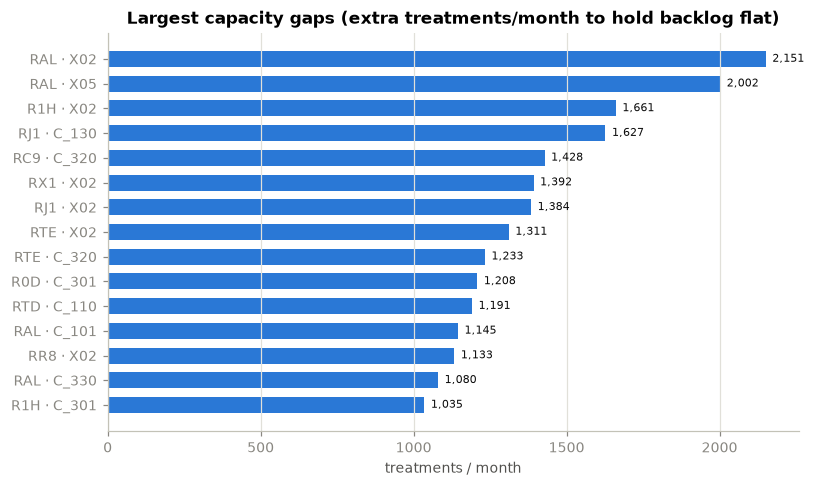

In [3]:
wi = w.set_index(ser)
rows = []
for (p, s), g in w.groupby(ser):
    g = g.sort_values("month")
    d = g["demand"].values
    growth = np.clip(d[-12:].sum() / max(d[-24:-12].sum(), 1), 0.5, 2.0)
    demand_fc = d[-12:] * growth                    # next 12 months = last year's shape x growth
    thr = g["throughput"].values[-6:].mean()        # capacity frozen at recent level
    backlog_now = g["backlog"].values[-1]
    backlog_12m = max(backlog_now + (demand_fc - thr).sum(), 0)
    rows.append({"provider_code": p, "specialty_code": s, "region": g["region"].iloc[0],
                 "backlog_now": backlog_now, "backlog_12m": round(backlog_12m),
                 "extra_per_month": max(round(demand_fc.mean() - thr), 0)})
proj = pd.DataFrame(rows)

growing = proj[proj["backlog_12m"] > proj["backlog_now"]]
print(f"units with growing backlog under do-nothing: {len(growing)} of {len(proj)}")
print(f"network capacity gap: {proj['extra_per_month'].sum():,} extra treatments/month")

top = proj.nlargest(15, "extra_per_month").iloc[::-1]
labels = top["provider_code"] + " · " + top["specialty_code"]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(labels, top["extra_per_month"], color="#2a78d6", height=0.65)
for i, v in enumerate(top["extra_per_month"].values):
    ax.text(v + top['extra_per_month'].max() * 0.01, i, f"{v:,.0f}", va="center", fontsize=7, color="#0b0b0b")
ax.set_title("Largest capacity gaps (extra treatments/month to hold backlog flat)")
ax.set_xlabel("treatments / month")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## Orchestration agent — drift monitor and the retrain trigger

For every series, compare the latest month's demand against its own history for that calendar
month (z-score). If more than 10% of series drift beyond |z| > 2, the agent orders a federated
retraining round — the rule that closes the loop between the two planes.

In [4]:
hist = w[w["month"] < LAST].copy()
hist["moy"] = hist["month"].str[5:7]
cur2 = w[w["month"] == LAST].copy()
cur2["moy"] = LAST[5:7]
stats = hist.groupby(ser + ["moy"])["demand"].agg(["mean", "std"]).reset_index()
cur2 = cur2.merge(stats, on=ser + ["moy"])
cur2["z"] = (cur2["demand"] - cur2["mean"]) / cur2["std"].clip(lower=1)

drifted = cur2[cur2["z"].abs() > 2]
share = len(drifted) / len(cur2)
print(f"drifted series (|z|>2): {len(drifted)} of {len(cur2)} = {share:.1%}")
print(f"DECISION: {'RETRAIN federation' if share > 0.10 else 'no retraining needed'} "
      f"(threshold 10%)")
print("\nlargest drifts:")
print(drifted.reindex(drifted["z"].abs().sort_values(ascending=False).index)
      [["provider_code", "specialty_code", "demand", "mean", "z"]].head(8).round(1).to_string(index=False))

drifted series (|z|>2): 151 of 694 = 21.8%
DECISION: RETRAIN federation (threshold 10%)

largest drifts:
provider_code specialty_code  demand   mean    z
          RYJ            X06   453.0  120.8 23.7
          RM1            X05  1132.0  333.0 14.3
          RTH          C_430   367.0  149.5 12.4
          RRK          C_130  2817.0 1953.5 11.9
          RDE          C_100   861.0 2829.2 -9.7
          RBN            X04  1693.0  968.8  9.6
          RDE            X06   298.0   88.8  8.8
          RHM          C_430   124.0   42.5  8.4


**How this connects to the federated plane**

- The monitoring/planning agents *consume* forecasts; today's stand-in forecaster is swappable
  for the A100-sweep winner with no other change.
- The orchestration agent's retrain trigger is what makes the system closed-loop:
  perception (drift) → decision (retrain or not) → action (federated round) → new forecasts.
- Everything computed here uses only aggregates a federation server may see — the privacy
  boundary holds by construction.